# Auditoría de alertas KYC por canal
## Resumen
Experimento sintético: calibración agrupada frente a pooled; resultados calculados abajo. No es detector de fraude validado.

## Contexto y método
Score fijo s=|residuo|, sin entrenamiento sobre calibración. Canales definidos antes de observar datos.

$p_g(s)=(1+\sum_i\mathbf{1}[S_{gi}\ge s])/(n_g+1)$. Alertar si $p_g\le0.05$. Empates con >= son conservadores.

Bajo intercambiabilidad de inliers dentro del canal, el rango proporciona validez marginal en calibración y nuevo caso, no una garantía condicional en la muestra fijada. No controlamos FDR de un lote ni garantizamos igualdad entre personas. 

In [1]:
from pathlib import Path
import json, csv
from IPython.display import display, Image
root=Path.cwd()
metrics=json.loads((root/'results/metrics.json').read_text())
print(json.dumps(metrics,indent=2))

{
  "fpr_gap": {
    "pooled": 0.09754166666666665,
    "channel": 0.0039000000000000007
  },
  "gap_reduction": 0.09364166666666665,
  "hypothesis_passed": true,
  "elapsed_seconds": 5.231555709999839,
  "peak_tracemalloc_bytes": 1244300,
  "max_rss_kib_linux": 54704,
  "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
  "platform": "Linux-6.18.55-x86_64-with-glibc2.39",
  "numpy": "2.3.5",
  "matplotlib": "3.10.8",
  "config": {
    "seeds": 60,
    "calibration_per_channel": 499,
    "test_inliers_per_channel": 2000,
    "test_outliers_per_channel": 500,
    "alpha": 0.05,
    "score_round_decimals": 1,
    "channel_scales": [
      1,
      4
    ],
    "anomaly_shift_sigma": 3,
    "drift_multiplier": 1.7,
    "sparse_calibration_per_channel": 9,
    "hypothesis": "stationary channel FPR disparity decreases by >=0.03 with channel calibration"
  }
}


## Datos y resultados
60 semillas; canales con escalas 1 y 4. Normalidad es una elección del experimento, no requisito del rango. Drift cambia solo la dispersión de inliers en evaluación. Sparse reduce calibración a 9 por canal.

{'scenario': 'stationary', 'method': 'pooled', 'channel': '0', 'kind': 'inlier', 'mean_rate': '0.0', 'seed_standard_error': '0.0'}
{'scenario': 'stationary', 'method': 'pooled', 'channel': '0', 'kind': 'outlier', 'mean_rate': '0.00016666666666666666', 'seed_standard_error': '7.19646282647288e-05'}
{'scenario': 'stationary', 'method': 'pooled', 'channel': '1', 'kind': 'inlier', 'mean_rate': '0.09754166666666665', 'seed_standard_error': '0.00190057572554009'}
{'scenario': 'stationary', 'method': 'pooled', 'channel': '1', 'kind': 'outlier', 'mean_rate': '0.9091333333333333', 'seed_standard_error': '0.002192110489744235'}
{'scenario': 'stationary', 'method': 'channel', 'channel': '0', 'kind': 'inlier', 'mean_rate': '0.0463', 'seed_standard_error': '0.0013620253280869203'}
{'scenario': 'stationary', 'method': 'channel', 'channel': '0', 'kind': 'outlier', 'mean_rate': '0.8407666666666667', 'seed_standard_error': '0.003389279098278329'}
{'scenario': 'stationary', 'method': 'channel', 'channel

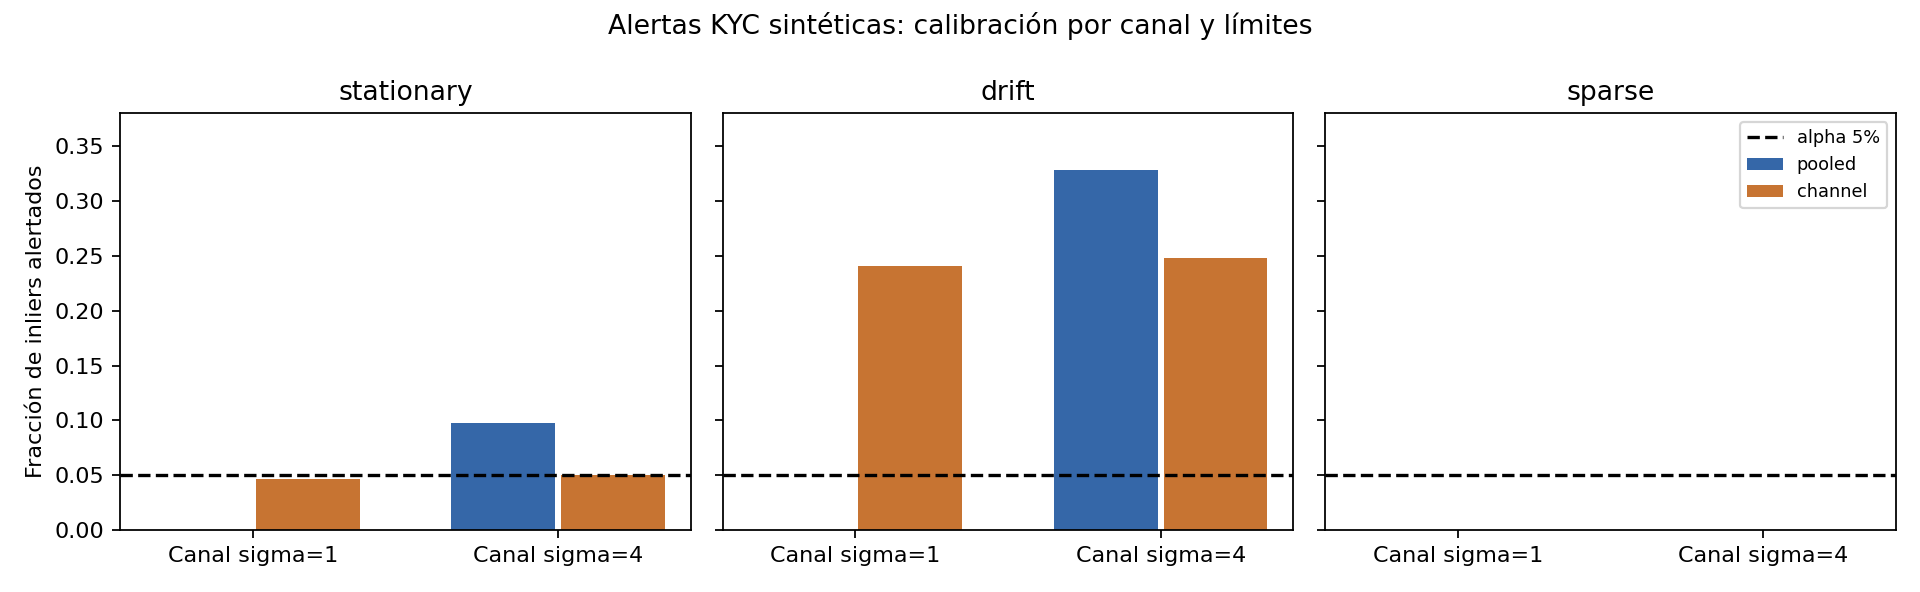

In [2]:
rows=list(csv.DictReader((root/'results/summary.csv').open()))
for row in rows: print(row)
display(Image(filename=str(root/'results/audit.png')))

## Comprobaciones

In [3]:
from src.conformal import TailCalibrator
assert TailCalibrator([1.,2.,2.,3.]).p_value(2)==.8
assert not TailCalibrator([0.]*9).alert(100,.05)
assert metrics['hypothesis_passed']
print('Checks passed; sparse abstains, drift invalidates nominal calibration.')

Checks passed; sparse abstains, drift invalidates nominal calibration.


## Conclusiones y límites
La dispersión distinta hace que un umbral global reparta mal las falsas alertas. Calibrar por canal corrige el escenario estacionario al coste de cambiar potencia por canal. No es una contribución teórica nueva: es una auditoría incremental del pipeline KYC. Deriva y pocos ejemplos muestran fallos intencionales. Siguiente paso: validar temporalmente con etiquetas aprobadas y carga de revisión humana.